# 🧠 14. Interpretabilidad: SHAP y LIME

Para el mejor modelo de cada tarea se explica **qué variables mueven la predicción**, en todo el conjunto (global) y en casos puntuales (local).

**Valores de Shapley (SHAP).** Vienen de la teoría de juegos cooperativos: las variables son "jugadores" que cooperan para producir la predicción, y el valor de Shapley de cada una es su contribución marginal promedio sobre todos los órdenes posibles en que se pueden agregar. Es la única forma de repartir la predicción que cumple a la vez:

- **eficiencia**: las contribuciones suman exactamente la predicción menos la predicción media, $f(x) = \phi_0 + \sum_j \phi_j$;
- **simetría**: dos variables que aportan lo mismo en todas las coaliciones reciben lo mismo;
- **aditividad**: para un ensamble que es suma de árboles, el SHAP del ensamble es la suma de los SHAP de los árboles;
- **jugador nulo**: una variable que nunca cambia la predicción recibe 0.

Para modelos de árboles se usa **TreeSHAP** (Lundberg et al., 2020), que calcula los valores **exactos** en tiempo polinomial recorriendo los árboles, sin muestrear coaliciones.

Las explicaciones se calculan en la escala en la que el modelo predice: $\log(1 + \text{venta})$ en regresión y log-odds de caída en clasificación (XGBoost) o probabilidad (Random Forest).

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from lime.lime_tabular import LimeTabularExplainer
from scipy import stats

from comun import estilo, a_log, SEED, AZUL, NARANJA, VERDE, GRIS, PALETA
from datos import preparar, partir, X_COLS
from experimentos import armar_maestra, cargar
from modelos import crear_modelo, ajustar

warnings.filterwarnings("ignore")
estilo()
train, test = partir(preparar())
maestra = armar_maestra()
NOMBRE = {"knn": "KNN", "ridge": "Ridge", "lasso": "Lasso", "arbol": "Árbol", "rf": "Random Forest", "xgb": "XGBoost",
          "svr": "SVR lineal", "nb": "Naive Bayes", "logistica": "Logística", "svm": "SVM lineal"}


def nombres_columnas(pre):
    num = list(pre.transformers_[0][2])
    dias = ["mar", "mié", "jue", "vie", "sáb", "dom"]
    return num + [f"día={d}" for d in dias]


def mejor_de(tarea, metrica, modelo=None):
    sub = maestra[(maestra["tarea"] == tarea)]
    if modelo:
        sub = sub[sub["modelo"] == modelo]
    fila = sub.loc[sub[metrica].idxmin() if metrica == "rmse_log_media" else sub[metrica].idxmax()]
    return fila["modelo"], fila["balanceo"], fila["optimizador"]

/opt/miniconda3/envs/ml_venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 📈 14.1 Regresión: el mejor modelo

El mejor modelo de regresión (menor RMSE log en el bucle externo, cap. 12) se reentrena con todo train y sus hiperparámetros finales. Las explicaciones se calculan sobre una muestra de 400 filas de test (TreeSHAP sobre un bosque profundo es costoso: crece con el número de hojas por la profundidad al cuadrado).

In [2]:
m_reg, _, o_reg = mejor_de("reg", "rmse_log_media")
r = cargar("reg", m_reg, "ninguno", o_reg)
mod_reg = crear_modelo("reg", m_reg, r["params_final"])
ajustar(mod_reg, train[X_COLS], train["venta_total"].to_numpy(), "reg", m_reg, "ninguno")
pre_r = mod_reg.regressor_.named_steps["pre"]; est_r = mod_reg.regressor_.named_steps["modelo"]
cols = nombres_columnas(pre_r)
muestra = test.sample(400, random_state=SEED)
Xm = pd.DataFrame(pre_r.transform(muestra[X_COLS]), columns=cols, index=muestra.index)
expl_r = shap.TreeExplainer(est_r)
sv_r = expl_r(Xm)
print(f"modelo: {NOMBRE[m_reg]} ({o_reg}); valor base φ0 = {sv_r.base_values[0]:.3f} en log (≈ {np.expm1(sv_r.base_values[0]) / 1e6:.2f} M COP)")
# eficiencia: φ0 + Σφ = predicción
err = np.abs(sv_r.values.sum(1) + sv_r.base_values - est_r.predict(Xm.to_numpy())).max()
print(f"comprobación de eficiencia: máx |φ0 + Σφ − f(x)| = {err:.2e}")

modelo: Random Forest (grid); valor base φ0 = 15.445 en log (≈ 5.10 M COP)
comprobación de eficiencia: máx |φ0 + Σφ − f(x)| = 1.54e-13


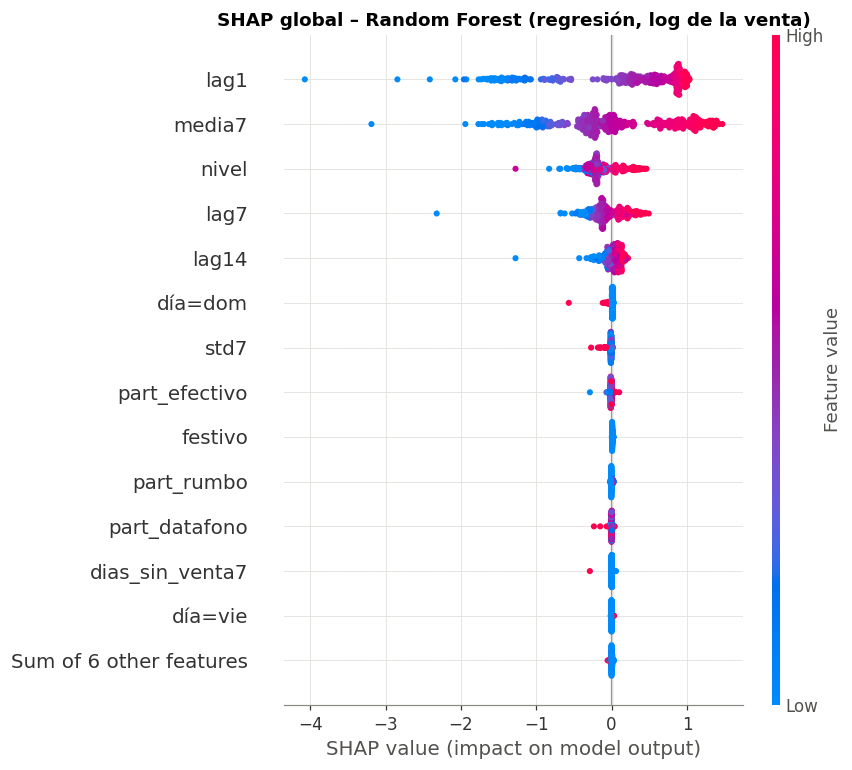

In [3]:
fig = plt.figure(figsize=(9, 6))
shap.plots.beeswarm(sv_r, max_display=14, show=False)
plt.title(f"SHAP global – {NOMBRE[m_reg]} (regresión, log de la venta)")
plt.tight_layout()

In [4]:
imp_r = pd.Series(np.abs(sv_r.values).mean(0), index=cols).sort_values(ascending=False)
(imp_r / imp_r.sum() * 100).round(1).rename("% de la importancia |SHAP| media").head(12).to_frame()

,% de la importancia |SHAP| media
lag1,37.90
media7,32.70
nivel,11.40
lag7,9.70
lag14,4.20
día=dom,0.80
std7,0.70
part_efectivo,0.50
festivo,0.50
part_rumbo,0.30


### Interpretación (global, regresión)

- El mejor modelo de regresión es **Random Forest**. La propiedad de **eficiencia** se cumple: $\phi_0 + \sum_j \phi_j$ reproduce la predicción con un error de $10^{-13}$. El valor base $\phi_0 = 15{,}4$ en log (≈ 5,1 M COP) es la predicción media.
- **Cuatro variables explican el 92 % de la importancia**: `lag1` (38 %), `media7` (33 %), `nivel` (11 %) y `lag7` (10 %). Es lo mismo que mostraban la ACF del capítulo 6 y los coeficientes del SVR en la entrega 1, pero con otro reparto. El bosque pone más peso en **lo que pasó ayer** (`lag1`), mientras que el SVR lineal se apoyaba más en `media7`.
- En el beeswarm, valores altos de `lag1` y `media7` (rojo) empujan la predicción hacia arriba y casi linealmente. El bosque aprende sobre todo la **persistencia del nivel**.
- El calendario (`día=dom`, `festivo`) y el mix de medios aportan menos del 1 % cada uno. El efecto del domingo existe (cap. 4 y 6), pero es de ~10 %: chico frente a las diferencias de nivel entre negocios, que son de órdenes de magnitud.

### Explicaciones locales: un acierto y un error grande

Se toma, dentro de la muestra, el negocio-día con el **menor** error absoluto en log (bien predicho) y el de **mayor** error (mal predicho).

bien predicho: N124 el 11 Sep (vie): real 5.770 M, predicho 5.769 M, error en log +0.00
error grande: N234 el 09 Sep (mié): real 0.001 M, predicho 9.012 M, error en log -8.72


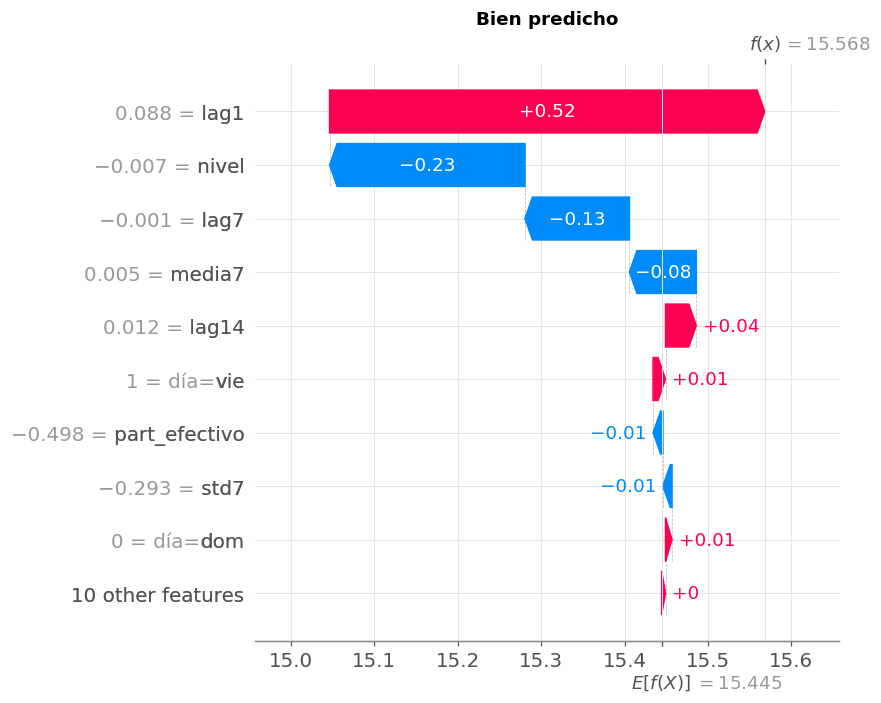

In [5]:
pred_m = est_r.predict(Xm.to_numpy())
err_m = a_log(muestra["venta_total"].to_numpy()) - pred_m
i_bien, i_mal = np.argmin(np.abs(err_m)), np.argmax(np.abs(err_m))
for etiqueta, i in [("bien predicho", i_bien), ("error grande", i_mal)]:
    f = muestra.iloc[i]
    print(f"{etiqueta}: {f['negocio']} el {f['fecha']:%d %b} ({['lun','mar','mié','jue','vie','sáb','dom'][f['fecha'].dayofweek]}): "
          f"real {f['venta_total'] / 1e6:.3f} M, predicho {np.expm1(pred_m[i]) / 1e6:.3f} M, error en log {err_m[i]:+.2f}")
fig = plt.figure(figsize=(9, 5))
shap.plots.waterfall(sv_r[i_bien], max_display=10, show=False)
plt.title("Bien predicho"); plt.tight_layout()

In [6]:
fig = plt.figure(figsize=(9, 5))
shap.plots.waterfall(sv_r[i_mal], max_display=10, show=False)
plt.title("Error grande"); plt.tight_layout()

### Interpretación (local, regresión)

- **Bien predicho** (N124, viernes 11 sep: real 5,770 M, predicho 5,769 M). Las contribuciones de `lag1` y `media7` llevan la predicción desde la media general hasta el nivel normal de ese negocio y las demás variables casi no la mueven. Es el caso típico: un negocio estable que vende lo de siempre.
- **Error grande** (N234, miércoles 9 sep: vendió ~1 000 COP y se pronosticaron 9 M). El modelo usó el nivel normal del negocio (`lag1`, `media7` altos) porque **nada en la información del día anterior anunciaba el cierre**: `dias_sin_venta7` era 0. Es el tipo de error que domina el RMSE en log (cap. 12.4) y que ningún modelo basado en el historial puede anticipar si el negocio no da señales antes.

## 🚨 14.2 Clasificación: el mejor modelo

In [7]:
m_clf, b_clf, o_clf = mejor_de("clf", "f1_media")
rc = cargar("clf", m_clf, b_clf, o_clf)
mod_clf = crear_modelo("clf", m_clf, rc["params_final"], b_clf)
ajustar(mod_clf, train[X_COLS], train["caida"].to_numpy(), "clf", m_clf, b_clf)
pre_c = mod_clf.named_steps["pre"]; est_c = mod_clf.named_steps["modelo"]
Xc = pd.DataFrame(pre_c.transform(muestra[X_COLS]), columns=cols, index=muestra.index)
# muestra enriquecida con todas las caídas de test, para que las explicaciones vean casos positivos
caidas = test[test["caida"] == 1]
Xc_pos = pd.DataFrame(pre_c.transform(caidas[X_COLS]), columns=cols, index=caidas.index)
Xc_all = pd.concat([Xc, Xc_pos[~Xc_pos.index.isin(Xc.index)]])
expl_c = shap.TreeExplainer(est_c)
sv_c = expl_c(Xc_all)
if sv_c.values.ndim == 3:  # Random Forest devuelve una explicación por clase: me quedo con "caída"
    sv_c = sv_c[:, :, 1]
print(f"modelo: {NOMBRE[m_clf]} con {b_clf} ({o_clf}); {len(Xc_all)} filas explicadas ({len(caidas)} caídas de test)")
fig = plt.figure(figsize=(9, 6))
shap.plots.beeswarm(sv_c, max_display=14, show=False)
plt.title(f"SHAP global – {NOMBRE[m_clf]} (clasificación de caída)")
plt.tight_layout()

modelo: XGBoost con balanced (bayes); 674 filas explicadas (288 caídas de test)


In [8]:
imp_c = pd.Series(np.abs(sv_c.values).mean(0), index=cols).sort_values(ascending=False)
pd.DataFrame({"% importancia regresión": (imp_r / imp_r.sum() * 100), "% importancia clasificación": (imp_c / imp_c.sum() * 100)}).sort_values("% importancia clasificación", ascending=False).round(1).head(12)

,% importancia regresión,% importancia clasificación
std7,0.70,17.30
lag1,37.90,16.90
lag14,4.20,9.60
media7,32.70,8.30
nivel,11.40,8.10
lag7,9.70,6.20
part_efectivo,0.50,5.70
part_datafono,0.30,5.40
festivo,0.50,4.10
part_rumbo,0.30,3.00


### Interpretación (global, clasificación)

- El mejor clasificador es **XGBoost con `class_weight` balanceado** (vía `sample_weight`).
- La importancia cambia mucho frente a la regresión: **`std7` pasa a ser la primera variable** (17 %, frente a 0,7 % en regresión). Para saber **cuánto** venderá un negocio importa su nivel; para saber si va a **caer**, importa qué tan **irregular** fue su última semana. Es el mismo hallazgo del capítulo 4b (la tasa de caídas se correlaciona con la volatilidad, ρ = 0,74).
- `lag1` sigue pesando (17 %): un ayer bajo o en cero anuncia una caída (las rachas del cap. 4b). `festivo` y los días de la semana ganan peso (4 % y ~3 %) porque las caídas se concentran en festivos.
- El **mix de medios** (`part_efectivo`, `part_datafono`) aporta ~11 % entre los dos. Distingue los tipos de negocio (cap. 4b): los KCO, que venden todo en efectivo, tienen más caídas.

In [9]:
# local: una caída detectada con alta confianza y una caída no detectada (falso negativo)
y_all = test.loc[Xc_all.index, "caida"].to_numpy()
p_all = mod_clf.predict_proba(test.loc[Xc_all.index, X_COLS])[:, 1]
detectada = np.where(y_all == 1, p_all, -1).argmax()
no_detectada = np.where(y_all == 1, -p_all, -2).argmax()
for etiqueta, i in [("caída detectada", detectada), ("caída NO detectada", no_detectada)]:
    f = test.loc[Xc_all.index[i]]
    print(f"{etiqueta}: {f['negocio']} el {f['fecha']:%d %b}: P(caída) = {p_all[i]:.3f}; venta {f['venta_total'] / 1e6:.3f} M "
          f"vs mediana de la semana {f['med7'] / 1e6:.3f} M; días sin venta en la semana: {f['dias_sin_venta7']:.0f}")
fig = plt.figure(figsize=(9, 5))
shap.plots.waterfall(sv_c[detectada], max_display=10, show=False)
plt.title("Caída detectada"); plt.tight_layout()

caída detectada: N060 el 05 Sep: P(caída) = 1.000; venta 0.000 M vs mediana de la semana 2.597 M; días sin venta en la semana: 2
caída NO detectada: N315 el 16 Sep: P(caída) = 0.000; venta 29.868 M vs mediana de la semana 80.092 M; días sin venta en la semana: 0


In [10]:
fig = plt.figure(figsize=(9, 5))
shap.plots.waterfall(sv_c[no_detectada], max_display=10, show=False)
plt.title("Caída no detectada (falso negativo)"); plt.tight_layout()

### Interpretación (local, clasificación)

- **Caída detectada** (N060, 5 sep: no vendió nada frente a una mediana de 2,6 M; P = 1,00). Ya tenía **2 días sin venta en la semana**. `lag1` bajo, `std7` alto y `dias_sin_venta7` empujan la probabilidad al máximo. Es una caída "anunciada": un negocio que ya venía cerrando días.
- **Caída no detectada** (N315, 16 sep: vendió 29,9 M frente a una mediana de 80 M; P ≈ 0). Es un negocio grande y estable, sin días sin venta y con una semana regular: todas las variables apuntan a "normal". La caída fue un evento **sin precedentes en su historial reciente** (posiblemente operativo: un cierre parcial, una falla de surtidor o del POS).
- **Conclusión:** el modelo detecta bien las caídas de negocios irregulares o que ya venían cayendo. Las caídas súbitas en negocios estables quedan fuera de su alcance con estas variables. Para detectarlas haría falta información del mismo día (ventas por hora, alarmas del POS), que sería fuga en el diseño actual.
- Nótese que la probabilidad es **extrema** (1,00 y 0,00). Es un síntoma de la mala calibración que produce el balanceo (cap. 13.4).

## 🍋 14.3 XGBoost: SHAP contra LIME

La guía pide comparar las dos técnicas sobre **XGBoost**. Se usa el mejor XGBoost de regresión (aunque no sea el mejor modelo general).

**LIME** (Ribeiro et al., 2016) explica una predicción ajustando un **modelo lineal local**: genera muestras perturbadas alrededor del caso, las pondera por cercanía (núcleo exponencial) y lee los coeficientes de la regresión ponderada. **SHAP** reparte la predicción con los valores de Shapley, que con TreeSHAP son **exactos** para el modelo.

| | LIME | SHAP (TreeSHAP) |
|---|---|---|
| Qué estima | Pendiente de una aproximación lineal **local** | Contribución marginal promedio de cada variable (**exacta**) |
| ¿Suma la predicción? | No necesariamente | Sí (eficiencia) |
| Depende de | La forma de perturbar, el ancho del núcleo y la semilla | El conjunto de referencia (fondo) |
| Estabilidad | Puede cambiar entre corridas | Determinista |

In [11]:
_, _, o_x = mejor_de("reg", "rmse_log_media", modelo="xgb")
rx = cargar("reg", "xgb", "ninguno", o_x)
mod_x = crear_modelo("reg", "xgb", rx["params_final"])
ajustar(mod_x, train[X_COLS], train["venta_total"].to_numpy(), "reg", "xgb", "ninguno")
pre_x = mod_x.regressor_.named_steps["pre"]; est_x = mod_x.regressor_.named_steps["modelo"]
Xx_tr = pre_x.transform(train[X_COLS]); Xx = pre_x.transform(muestra[X_COLS])
sv_x = shap.TreeExplainer(est_x)(pd.DataFrame(Xx, columns=cols))
lime_exp = LimeTabularExplainer(Xx_tr, feature_names=cols, mode="regression", discretize_continuous=False, random_state=SEED)

# 40 casos: correlación de rangos entre |SHAP| y |LIME| por caso, y coincidencia de la variable más importante
casos = np.random.default_rng(SEED).choice(len(Xx), 40, replace=False)
filas = []
for i in casos:
    e = lime_exp.explain_instance(Xx[i], est_x.predict, num_features=len(cols), num_samples=2000)
    w = pd.Series(dict(e.as_list())).reindex(cols).fillna(0)
    s = pd.Series(sv_x.values[i], index=cols)
    filas.append({"caso": i, "Spearman |SHAP| vs |LIME|": stats.spearmanr(s.abs(), w.abs())[0],
                  "misma variable top": s.abs().idxmax() == w.abs().idxmax(),
                  "top-3 en común": len(set(s.abs().nlargest(3).index) & set(w.abs().nlargest(3).index)),
                  "top SHAP": s.abs().idxmax(), "top LIME": w.abs().idxmax()})
cmp_ = pd.DataFrame(filas)
print(f"Spearman medio entre |SHAP| y |LIME|: {cmp_['Spearman |SHAP| vs |LIME|'].mean():.2f}")
print(f"misma variable más importante: {cmp_['misma variable top'].mean():.0%} de los casos; top-3 en común (media): {cmp_['top-3 en común'].mean():.1f}")
cmp_[["top SHAP", "top LIME"]].value_counts().head(8).rename("casos").to_frame()

Spearman medio entre |SHAP| y |LIME|: 0.58
misma variable más importante: 75% de los casos; top-3 en común (media): 2.4


,,casos
top SHAP,top LIME,
lag1,lag1,30
lag7,lag1,7
media7,lag1,3


In [12]:
# el caso de error grande de 14.1, explicado con las dos técnicas, y la estabilidad de LIME con 5 semillas
i = int(np.where(muestra.index == muestra.index[i_mal])[0][0])
s = pd.Series(sv_x.values[i], index=cols)
lime_runs = []
for sem in [1, 2, 3, 4, 5]:
    le = LimeTabularExplainer(Xx_tr, feature_names=cols, mode="regression", discretize_continuous=False, random_state=sem)
    lime_runs.append(pd.Series(dict(le.explain_instance(Xx[i], est_x.predict, num_features=len(cols), num_samples=2000).as_list())).reindex(cols).fillna(0))
lime_runs = pd.concat(lime_runs, axis=1)
comp = pd.DataFrame({"SHAP": s, "LIME (media 5 semillas)": lime_runs.mean(1), "LIME desv. entre semillas": lime_runs.std(1)})
comp = comp.loc[comp["SHAP"].abs().sort_values(ascending=False).index].head(8)
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(comp))
ax.barh(y - 0.2, comp["SHAP"], height=0.4, color=AZUL, label="SHAP (contribución, log)")
ax.barh(y + 0.2, comp["LIME (media 5 semillas)"], height=0.4, xerr=comp["LIME desv. entre semillas"], color=NARANJA, label="LIME (peso local)")
ax.set_yticks(y); ax.set_yticklabels(comp.index); ax.invert_yaxis(); ax.axvline(0, color=GRIS)
ax.set_title("XGBoost, caso con error grande: SHAP contra LIME"); ax.legend(fontsize=8)
plt.tight_layout()
print(f"suma SHAP + base = {s.sum() + sv_x.base_values[i]:.3f} = predicción {est_x.predict(Xx[i:i + 1])[0]:.3f}")
comp.round(3)

suma SHAP + base = 15.924 = predicción 15.924


,SHAP,LIME (media 5 semillas),LIME desv. entre semillas
lag1,0.69,1.45,0.04
nivel,-0.39,-0.18,0.02
media7,0.16,0.59,0.02
lag7,-0.11,0.28,0.01
lag14,0.11,0.21,0.03
festivo,0.01,-0.01,0.01
día=dom,0.01,-0.00,0.03
dias_sin_venta7,0.00,0.02,0.03


### Interpretación: SHAP contra LIME

- **Coinciden en lo grueso.** En 40 casos, la variable más importante es la misma en el 75 % y comparten en promedio 2,4 de las 3 principales. Ambas reconocen que `lag1` domina.
- **Difieren en el detalle.** La correlación de rangos media entre |SHAP| y |LIME| es solo **0,58**, y en el caso de error grande las magnitudes no se parecen: LIME le da a `lag1` un peso de 1,45 y a `media7` 0,59, mientras que SHAP les asigna 0,69 y 0,16. Hasta cambia el **signo** de `lag7`. Hay tres razones:
  1. **Qué miden.** LIME da la **pendiente** de una recta ajustada en una vecindad. SHAP da la **contribución** de la variable a esta predicción frente a la media. Un árbol es escalonado: cerca del punto la pendiente puede ser grande aunque la contribución total sea pequeña, o al revés.
  2. **Colinealidad.** `lag1`, `lag7`, `media7` y `nivel` están muy correlacionadas (VIF alto, cap. 4). LIME perturba cada variable **por separado**, así que genera combinaciones irreales (ayer alto pero semana baja) y reparte el peso entre variables colineales de forma arbitraria. SHAP con TreeSHAP sigue las rutas de los árboles con la distribución de los datos de entrenamiento.
  3. **Eficiencia.** Los SHAP suman exactamente la predicción (15,924); los pesos de LIME no tienen por qué sumar nada.
- **Estabilidad.** En este caso LIME fue bastante estable entre 5 semillas (desviaciones de 0,01–0,04), porque usa 2 000 muestras. Con menos muestras o con discretización, las explicaciones de LIME varían más. TreeSHAP es determinista.
- **¿Cuándo divergen más?** Con variables colineales (como aquí), en modelos muy no lineales o con interacciones fuertes (donde una recta local no representa bien el modelo) y en puntos cerca de los cortes de los árboles. Para un modelo de árboles, **SHAP es la explicación de referencia**; LIME sirve como chequeo de sensibilidad local.